# Week 3, Monday: K-Means Clustering, Elbow Method & Silhouette Score
Dataset: **Mall Customers** (200 customers: Age, Annual Income, Spending Score). We want to find **groups of similar customers** without any labels. That is **unsupervised learning**.




## 0. Setup and load the data

In [1]:
import numpy as np, pandas as pd, os
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, silhouette_samples
sns.set_theme(style='whitegrid')
np.random.seed(42)

if os.path.exists('Mall_Customers.csv'):
    df = pd.read_csv('Mall_Customers.csv')
    USING_REAL_DATA = True
else:
    USING_REAL_DATA = False
    print('!' * 70)
    print('WARNING: Mall_Customers.csv NOT FOUND. Using SYNTHETIC practice data.')
    print('Upload the real file and re-run before you submit or report any results.')
    print('!' * 70)
    rng = np.random.RandomState(1)
    centres = [(25, 20), (25, 80), (55, 50), (88, 17), (88, 82)]
    inc, spend = [], []
    for ci, cs in centres:
        inc += list(rng.normal(ci, 7, 40)); spend += list(rng.normal(cs, 8, 40))
    df = pd.DataFrame({'CustomerID': range(1, 201),
                       'Genre': rng.choice(['Male', 'Female'], 200),
                       'Age': rng.randint(18, 70, 200),
                       'Annual Income (k$)': np.clip(inc, 15, 137).round().astype(int),
                       'Spending Score (1-100)': np.clip(spend, 1, 99).round().astype(int)})

df = df.rename(columns={'Gender': 'Genre'})           # some copies use 'Gender'
print('Using real data:', USING_REAL_DATA, '| shape:', df.shape)
df.head()

Using real data: True | shape: (200, 5)


,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


## 1. Explore the data (EDA)

In [2]:
display(df.describe().round(1))
print('Missing values:', int(df.isnull().sum().sum()))
print(df['Genre'].value_counts())

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.0,200.0,200.0,200.0
mean,100.5,38.8,60.6,50.2
std,57.9,14.0,26.3,25.8
min,1.0,18.0,15.0,1.0
25%,50.8,28.8,41.5,34.8
50%,100.5,36.0,61.5,50.0
75%,150.2,49.0,78.0,73.0
max,200.0,70.0,137.0,99.0


Missing values: 0
Genre
Female    112
Male       88
Name: count, dtype: int64


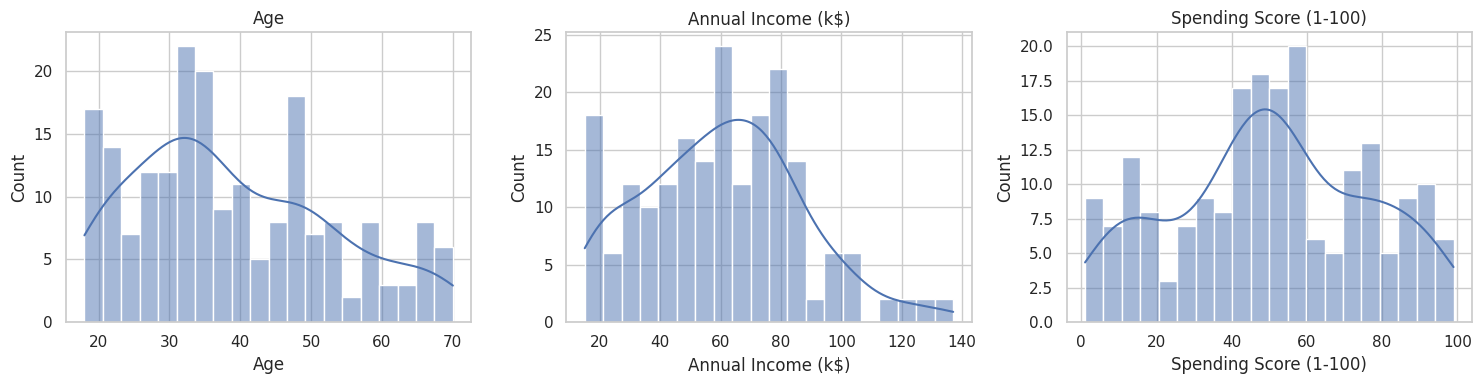

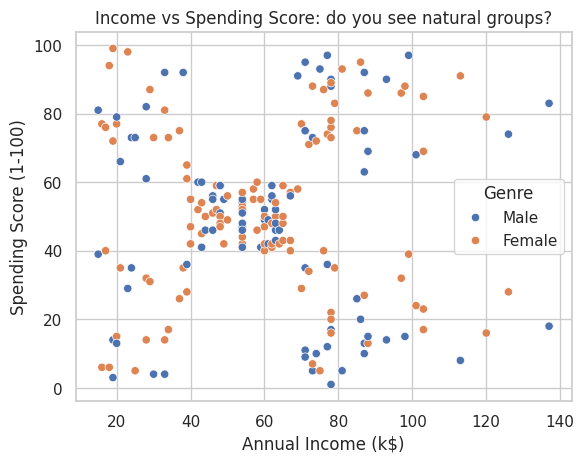

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, col in zip(ax, ['Age', 'Annual Income (k$)', 'Spending Score (1-100)']):
    sns.histplot(df[col], bins=20, kde=True, ax=a); a.set_title(col)
plt.tight_layout(); plt.show()

sns.scatterplot(data=df, x='Annual Income (k$)', y='Spending Score (1-100)', hue='Genre')
plt.title('Income vs Spending Score: do you see natural groups?'); plt.show()

## 2. Scale the features
K-Means uses **distances**, so a feature with bigger numbers would dominate. We standardise (mean 0, std 1), exactly as with kNN.

We start with the classic two features: **Annual Income** and **Spending Score**.

In [4]:
features = ['Annual Income (k$)', 'Spending Score (1-100)']
X = df[features].values
scaler = StandardScaler().fit(X)
Xs = scaler.transform(X)
print('Before scaling (mean, std):', X.mean(0).round(1), X.std(0).round(1))
print('After scaling  (mean, std):', Xs.mean(0).round(2), Xs.std(0).round(2))

Before scaling (mean, std): [60.6 50.2] [26.2 25.8]
After scaling  (mean, std): [-0. -0.] [1. 1.]


## 3. How K-Means works, step by step (from scratch)
1. Pick **k** starting centres at random.
2. **Assign** every point to its nearest centre.
3. **Move** each centre to the mean of the points assigned to it.
4. Repeat 2-3 until the centres stop moving.

In [5]:
def simple_kmeans(X, k, iters=10, seed=0):
    rng = np.random.RandomState(seed)
    centres = X[rng.choice(len(X), k, replace=False)]
    for i in range(iters):
        dists = np.linalg.norm(X[:, None, :] - centres[None, :, :], axis=2)   # distance of each point to each centre
        labels = dists.argmin(axis=1)                                          # step 2: assign
        new_centres = np.array([X[labels == j].mean(axis=0) if (labels == j).any() else centres[j] for j in range(k)])  # step 3: move
        moved = np.abs(new_centres - centres).max()
        centres = new_centres
        if moved < 1e-6: break
    inertia = ((X - centres[labels]) ** 2).sum()
    return labels, centres, inertia, i + 1

labels_me, centres_me, inertia_me, n_iter = simple_kmeans(Xs, k=5)
print(f'My K-Means (k=5): converged in {n_iter} iterations, inertia = {inertia_me:.2f}')
sk = KMeans(n_clusters=5, n_init=10, random_state=42).fit(Xs)
print(f'scikit-learn KMeans (k=5): inertia = {sk.inertia_:.2f}')

My K-Means (k=5): converged in 7 iterations, inertia = 65.57
scikit-learn KMeans (k=5): inertia = 65.57


Both should give very similar inertia (a different random start can land on a slightly different answer, which is why scikit-learn runs the algorithm `n_init=10` times and keeps the best).

**Inertia** = the sum of squared distances from each point to its own cluster centre. Smaller means tighter clusters.

## 4. Choosing k, method 1: the Elbow
Inertia **always falls** as k grows (with k = number of points it would be 0). So we look for the **elbow**: the point where adding another cluster stops helping much.

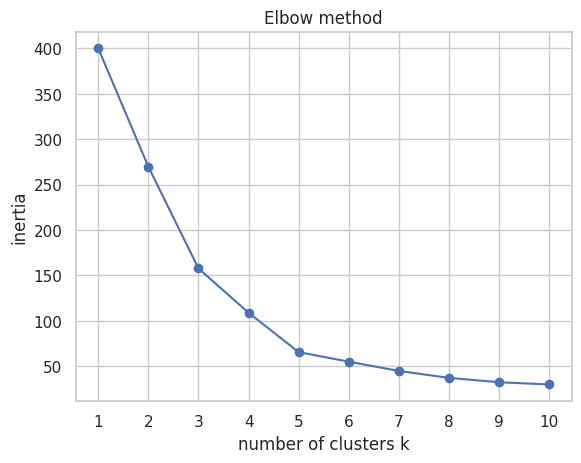

 k  inertia  drop vs previous k
 1    400.0                 NaN
 2    269.7               130.3
 3    157.7               112.0
 4    108.9                48.8
 5     65.6                43.4
 6     55.1                10.5
 7     44.9                10.2
 8     37.2                 7.6
 9     32.4                 4.8
10     30.0                 2.4


In [6]:
ks = range(1, 11)
inertias = [KMeans(n_clusters=k, n_init=10, random_state=42).fit(Xs).inertia_ for k in ks]
plt.plot(list(ks), inertias, 'o-'); plt.xticks(list(ks))
plt.xlabel('number of clusters k'); plt.ylabel('inertia'); plt.title('Elbow method'); plt.show()
print(pd.DataFrame({'k': list(ks), 'inertia': np.round(inertias, 1),
                    'drop vs previous k': [np.nan] + list(np.round(-np.diff(inertias), 1))}).to_string(index=False))

## 5. Choosing k, method 2: the Silhouette score
For each point: **a** = average distance to its own cluster, **b** = average distance to the *nearest other* cluster. Its silhouette is (b - a) / max(a, b), from -1 to 1.
- Near **+1**: well inside its own cluster, far from others.
- Near **0**: on the boundary between two clusters.
- **Negative**: probably in the wrong cluster.

The score for a clustering is the **average over all points**. Higher is better. It is only defined for k >= 2.

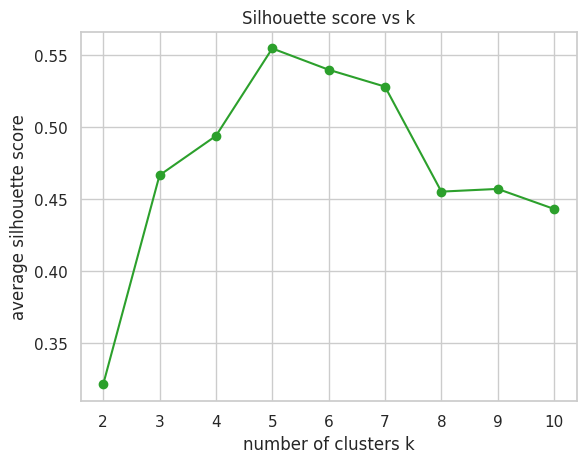

 k  silhouette
 2       0.321
 3       0.467
 4       0.494
 5       0.555
 6       0.540
 7       0.528
 8       0.455
 9       0.457
10       0.443
Best k by silhouette: 5


In [7]:
ks2 = range(2, 11)
sil = [silhouette_score(Xs, KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(Xs)) for k in ks2]
plt.plot(list(ks2), sil, 'o-', color='tab:green'); plt.xticks(list(ks2))
plt.xlabel('number of clusters k'); plt.ylabel('average silhouette score'); plt.title('Silhouette score vs k'); plt.show()
best_k = list(ks2)[int(np.argmax(sil))]
print(pd.DataFrame({'k': list(ks2), 'silhouette': np.round(sil, 3)}).to_string(index=False))
print('Best k by silhouette:', best_k)

## 6. Silhouette plot for one k: which clusters are tight, and which are fuzzy?

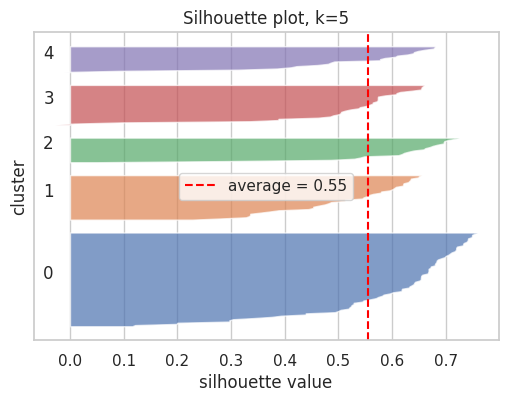

In [8]:
def silhouette_plot(k):
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(Xs)
    s = silhouette_samples(Xs, km.labels_)
    fig, ax = plt.subplots(figsize=(6, 4)); y0 = 10
    for c in range(k):
        v = np.sort(s[km.labels_ == c]); ax.fill_betweenx(np.arange(y0, y0 + len(v)), 0, v, alpha=0.7)
        ax.text(-0.05, y0 + len(v) / 2, str(c)); y0 += len(v) + 10
    ax.axvline(s.mean(), color='red', ls='--', label=f'average = {s.mean():.2f}')
    ax.set(xlabel='silhouette value', ylabel='cluster', title=f'Silhouette plot, k={k}', yticks=[]); ax.legend(); plt.show()
silhouette_plot(best_k)

Each coloured bar group is one cluster. Wide, long bars reaching toward 1 mean a tight cluster. Bars that reach below the red average line, or that go negative, mean a fuzzier cluster.

## 7. Fit the final model and plot the clusters and centroids

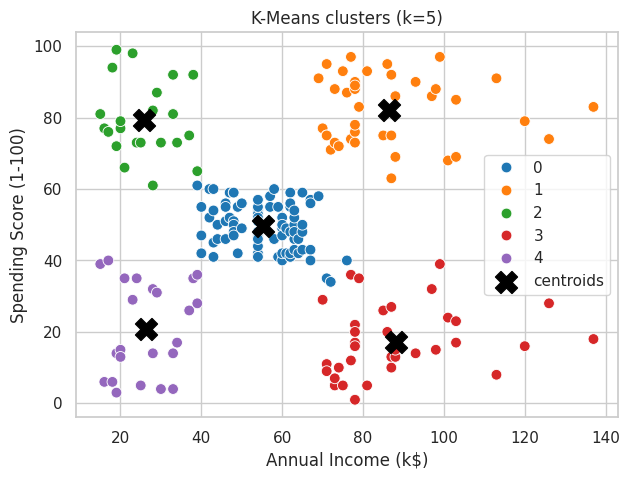

Silhouette: 0.555 | inertia: 65.6
Cluster
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64


In [9]:
K = best_k          # change this to the k YOU decide on after looking at the elbow and silhouette
km = KMeans(n_clusters=K, n_init=10, random_state=42).fit(Xs)
df['Cluster'] = km.labels_
centres = scaler.inverse_transform(km.cluster_centers_)      # back to the original units (k$ and score)

plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x=features[0], y=features[1], hue='Cluster', palette='tab10', s=60)
plt.scatter(centres[:, 0], centres[:, 1], c='black', marker='X', s=250, label='centroids')
plt.title(f'K-Means clusters (k={K})'); plt.legend(); plt.show()
print('Silhouette:', round(silhouette_score(Xs, km.labels_), 3), '| inertia:', round(km.inertia_, 1))
print(df['Cluster'].value_counts().sort_index())

## 8. Describe each cluster in words (profiling)

In [10]:
profile = df.groupby('Cluster')[['Age', 'Annual Income (k$)', 'Spending Score (1-100)']].mean().round(1)
profile['size'] = df['Cluster'].value_counts().sort_index()
profile

,Age,Annual Income (k$),Spending Score (1-100),size
Cluster,,,,
0,42.7,55.3,49.5,81
1,32.7,86.5,82.1,39
2,25.3,25.7,79.4,22
3,41.1,88.2,17.1,35
4,45.2,26.3,20.9,23


## 9. Why scaling matters: break it on purpose
Same data, but we express Annual Income in **dollars** instead of thousands of dollars. Nothing about the customers changed, but the numbers are now 1000 times larger.

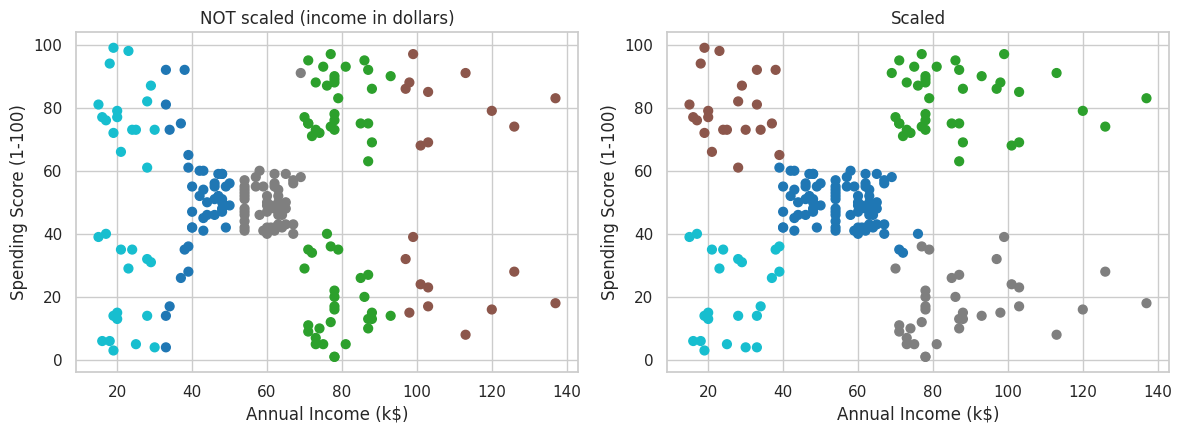

In [11]:
X_dollars = np.c_[df['Annual Income (k$)'] * 1000, df['Spending Score (1-100)']]
raw = KMeans(n_clusters=K, n_init=10, random_state=42).fit(X_dollars)

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].scatter(df[features[0]], df[features[1]], c=raw.labels_, cmap='tab10', s=40)
ax[0].set_title('NOT scaled (income in dollars)'); ax[0].set(xlabel=features[0], ylabel=features[1])
ax[1].scatter(df[features[0]], df[features[1]], c=km.labels_, cmap='tab10', s=40)
ax[1].set_title('Scaled'); ax[1].set(xlabel=features[0], ylabel=features[1])
plt.tight_layout(); plt.show()